# Explainability: Best Models for each Configuration

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
shap.initjs()

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV

/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_train = pd.read_csv('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/5. Classification/df_train.csv')
df_test = pd.read_csv('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/5. Classification/df_test.csv')

In [3]:
n_classes = 3

In [4]:
lab_encoder = joblib.load('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/3. Data Understanding and Prep/label_encoder.pkl')

In [5]:
for i, class_name in enumerate(lab_encoder.classes_):
    print(f"Classe {i} = {class_name}")

Classe 0 = inflow
Classe 1 = outflow
Classe 2 = stable


1. 

In [6]:
cols_to_drop = df_train.filter(regex=r"2020|2021").columns.tolist()
df_train = df_train.drop(cols_to_drop, axis = 1)
df_test = df_test.drop(cols_to_drop, axis = 1)

In [7]:
y_test = df_test['target']
x_test = df_test.drop('target', axis=1)

In [8]:
y = df_train['target']
X = df_train.drop('target', axis = 1)

In [9]:
x_train, x_val, y_train, y_val = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

In [10]:
columns_to_scale = df_train.filter(regex=r"\d{4}").columns.tolist()
scaler = StandardScaler()

x_train[columns_to_scale] = scaler.fit_transform(x_train[columns_to_scale])
x_val[columns_to_scale] = scaler.transform(x_val[columns_to_scale])
df_test[columns_to_scale] = scaler.transform(df_test[columns_to_scale])

In [11]:
x_train.shape

(344, 283)

2. Caricamento dei modelli migliori con e senza city

In [12]:
model_city = joblib.load('/Users/laviniarotellini/Library/CloudStorage/OneDrive-UniversityofPisa(2)/models_articolo/Modelli a due anni/_svm_tesi_due_city.pkl')
#model_no_city = joblib.load('/Users/laviniarotellini/Library/CloudStorage/OneDrive-UniversityofPisa(2)/models-tesi/Modelli a due anni senza city/log_reg_due_nocity.pkl')

3. SHAP

3.1 City

In [13]:
background = shap.kmeans(x_train, 50)

In [14]:
explainer_city = shap.KernelExplainer(model_city.predict_proba, background)
x_train_sample = x_train.sample(100, random_state=42)
shap_values_city = explainer_city.shap_values(x_train_sample)

100%|██████████| 100/100 [02:55<00:00,  1.76s/it]


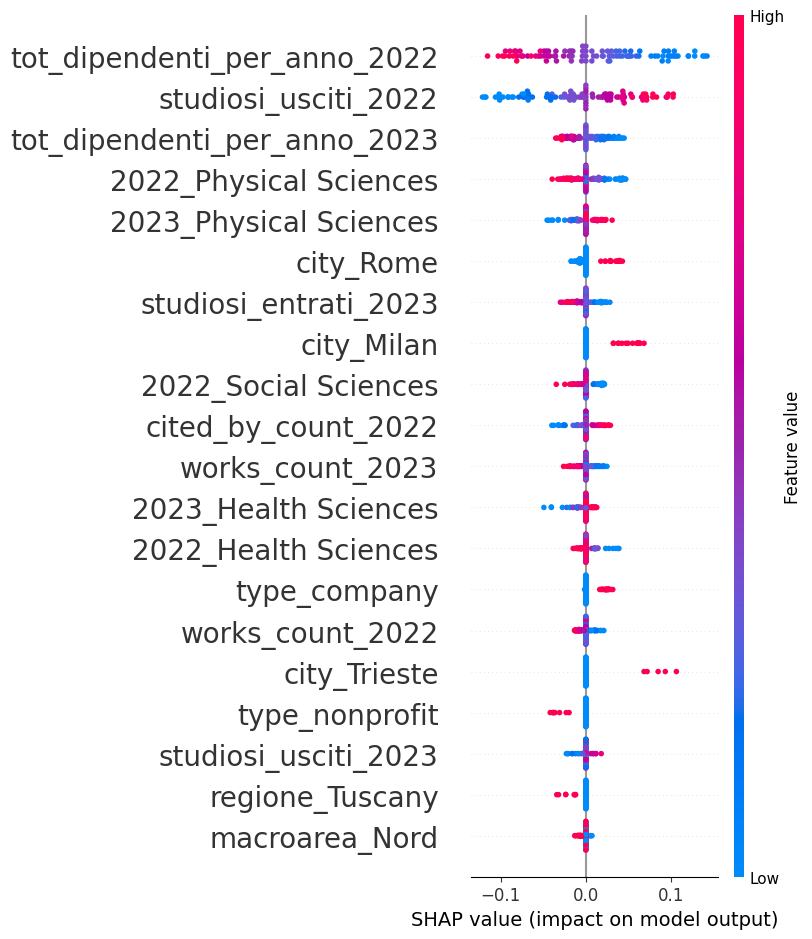

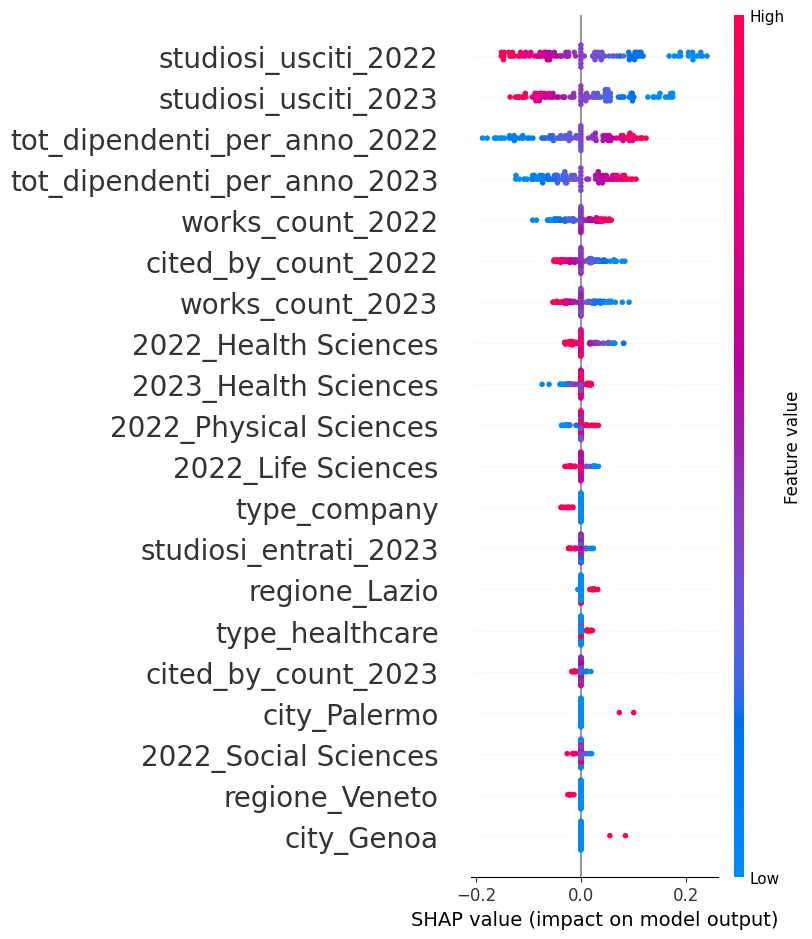

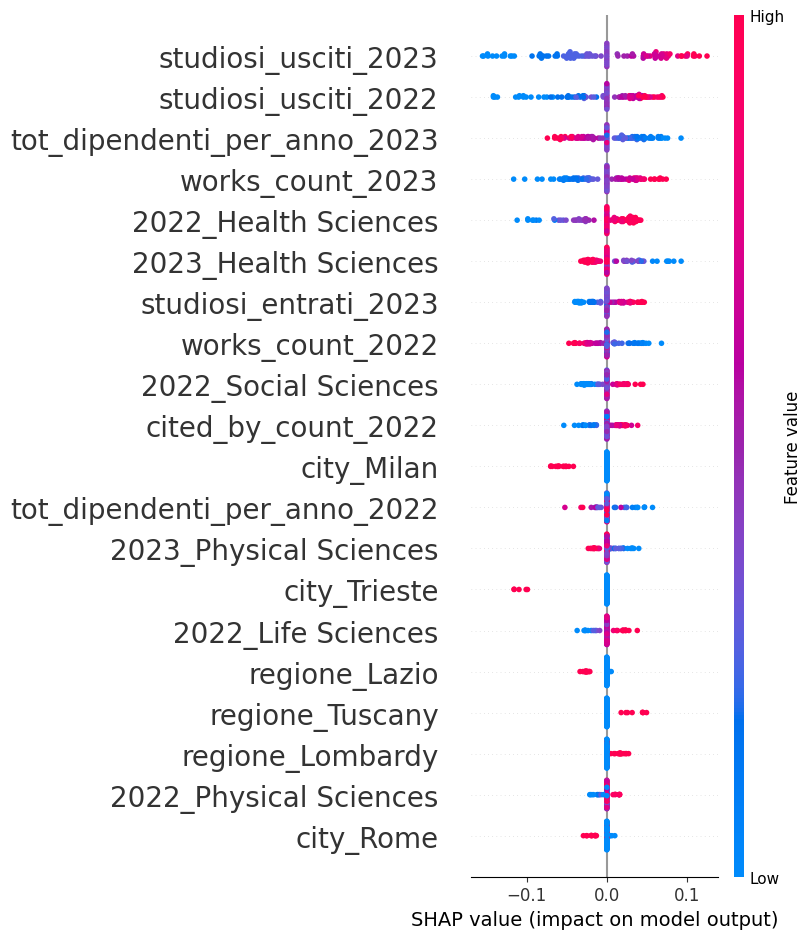

In [15]:
# shap_values_float_city = shap_values_city.values.astype(np.float64)
# x_test_float_city = np.array(x_val, dtype=np.float64)

# for i in range(n_classes):
#     print(f"\n--- Classe {i} ---")
#     shap.summary_plot(shap_values_city[:, :, i], x_train_sample, show=True)


for i in range(n_classes):
    plt.figure()
    shap.summary_plot(
        shap_values_city[:, :, i],
        x_train_sample,
        show=False  # ← importante: non mostrare subito
    )
    
    ax = plt.gca()
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=20)  # label features (asse Y)
    ax.set_xlabel(ax.get_xlabel(), fontsize=14)             # label asse X
    ax.tick_params(axis='x', labelsize=12)                  # tick asse X
    
    plt.tight_layout()
    plt.savefig(f"classe_{i}.png", dpi=150, bbox_inches='tight')
    plt.show()

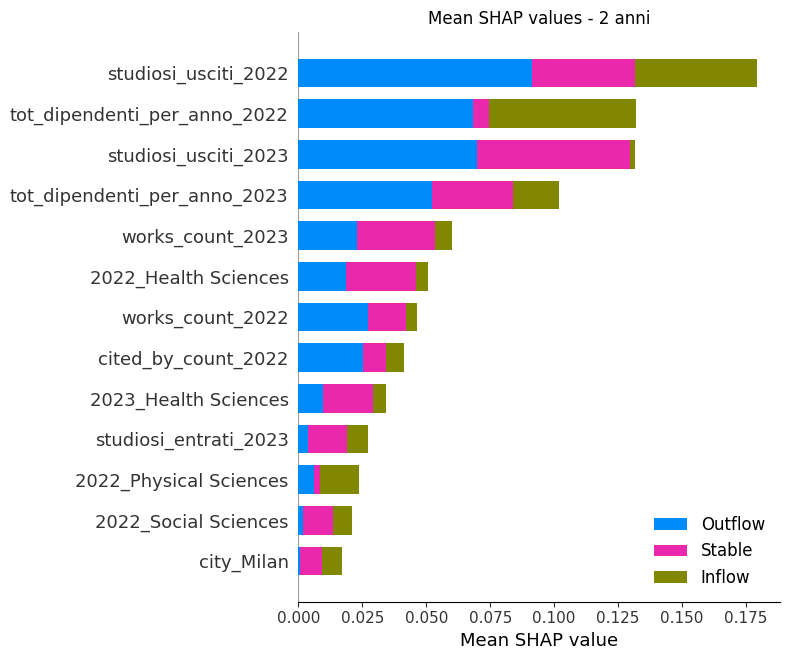

In [16]:
shap.summary_plot(shap_values_city, x_train, plot_type="bar", max_display=13, show= False, class_names = ['Inflow', 'Outflow', 'Stable'] )
plt.xlabel("Mean SHAP value")
plt.title("Mean SHAP values - 2 anni")
plt.tight_layout()
plt.show()

In [17]:
feature_names = x_train.columns.tolist()


Classe 0
                          feature  importance
4    tot_dipendenti_per_anno_2022    0.057368
5            studiosi_usciti_2022    0.047640
7    tot_dipendenti_per_anno_2023    0.017977
13         2022_Physical Sciences    0.015284
17         2023_Physical Sciences    0.009399
231                     city_Rome    0.008220
9           studiosi_entrati_2023    0.008156
175                    city_Milan    0.007755
12           2022_Social Sciences    0.007423
3             cited_by_count_2022    0.007146

Classe 1
                         feature  importance
5           studiosi_usciti_2022    0.091206
8           studiosi_usciti_2023    0.069898
4   tot_dipendenti_per_anno_2022    0.068399
7   tot_dipendenti_per_anno_2023    0.052144
2               works_count_2022    0.027061
3            cited_by_count_2022    0.025304
0               works_count_2023    0.023021
10          2022_Health Sciences    0.018468
14          2023_Health Sciences    0.009601
13        2022_Physical 

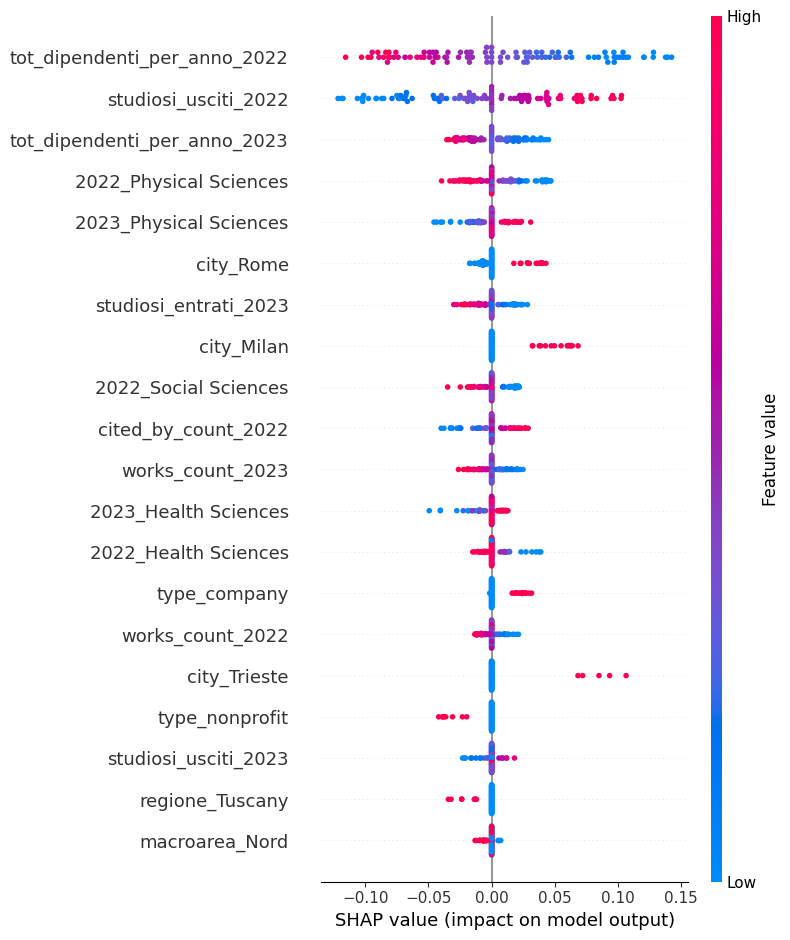

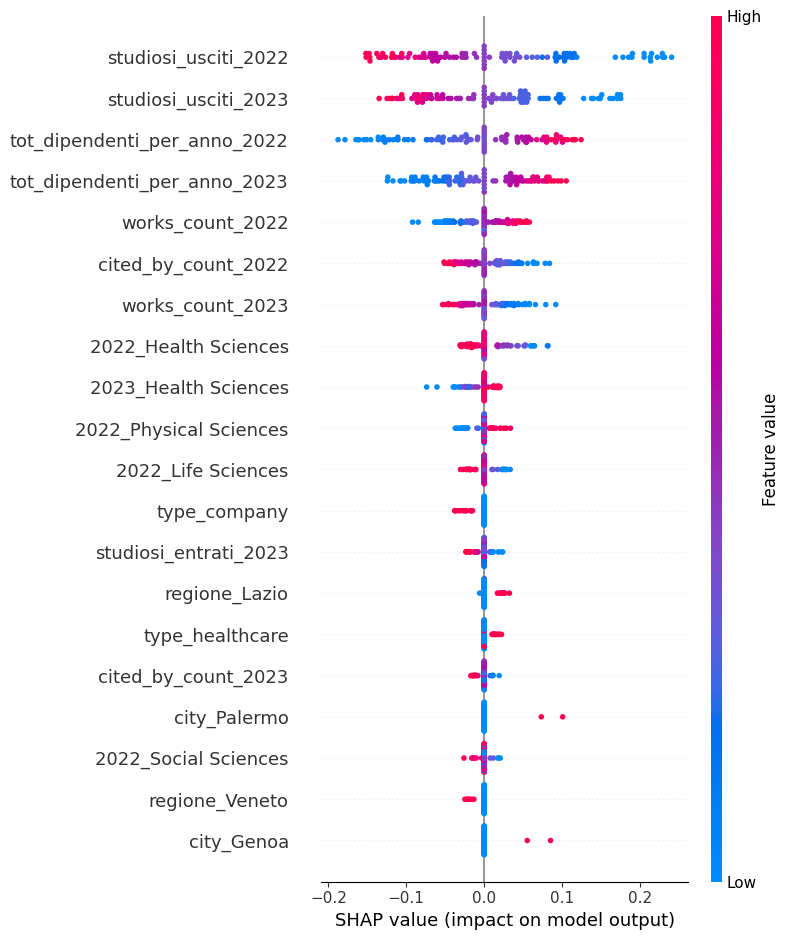

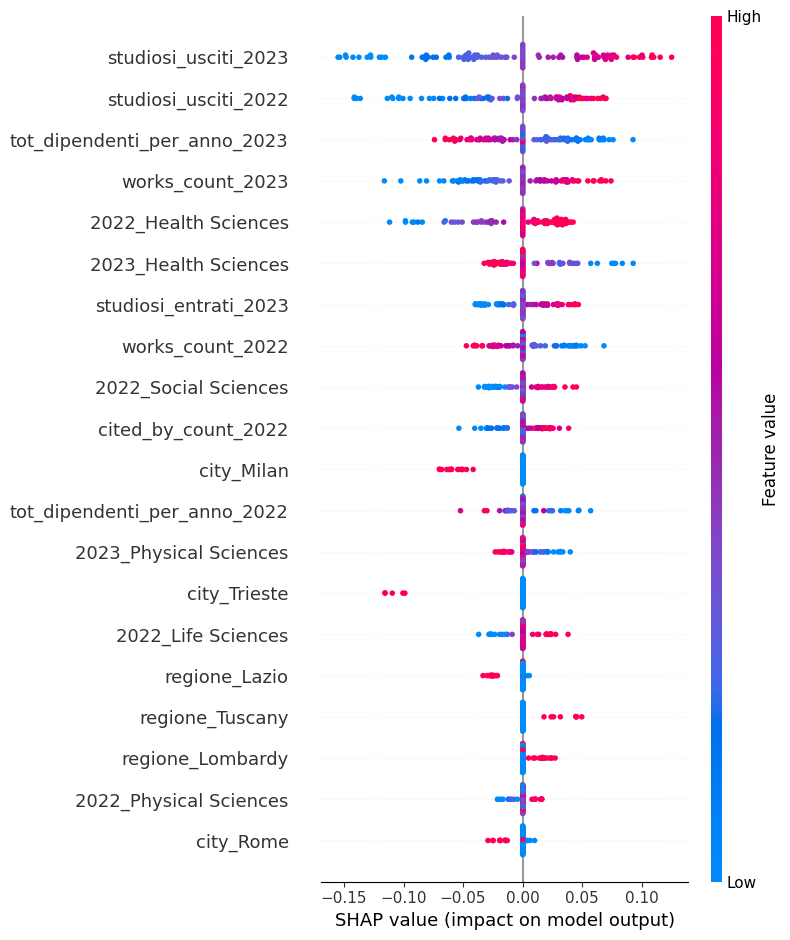

In [18]:
for i in range(n_classes):
    shap_vals_class = shap_values_city[:, :, i]  # tutte le osservazioni, classe i
    
    mean_importance = np.abs(shap_vals_class).mean(axis=0)
    
    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": mean_importance
    }).sort_values(by="importance", ascending=False)
    
    print(f"\nClasse {i}")
    print(importance_df.head(10))

for i in range(n_classes):
    shap.summary_plot(
        shap_values_city[:, :, i],
        x_train_sample,
        feature_names=feature_names,
        show=True
    )

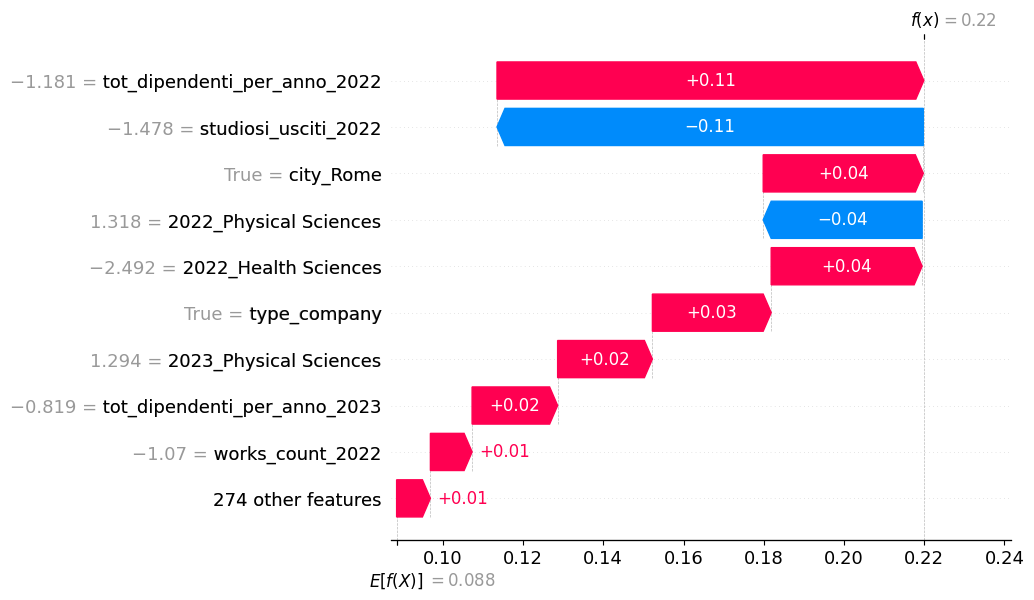

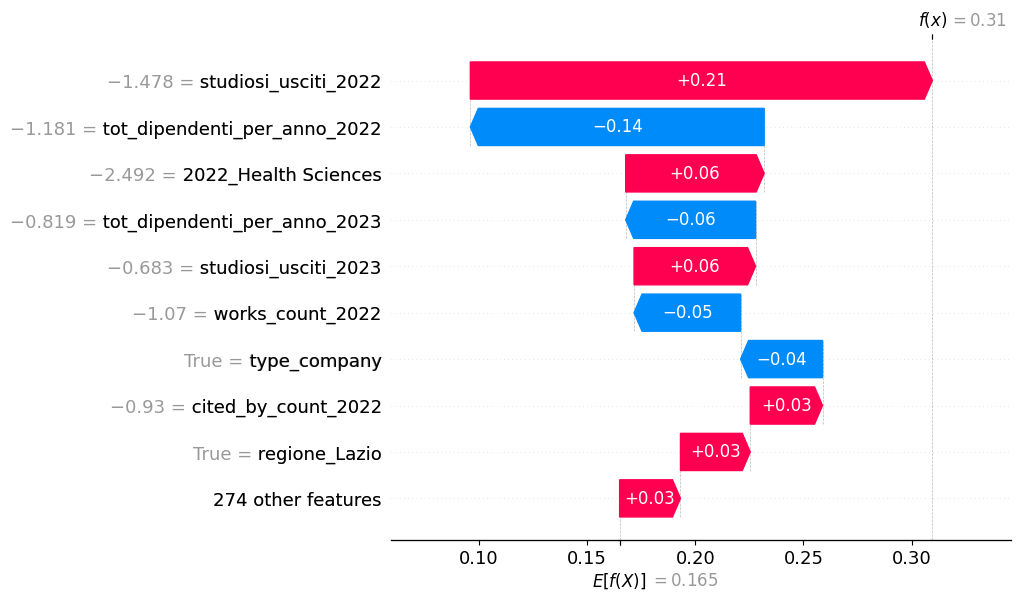

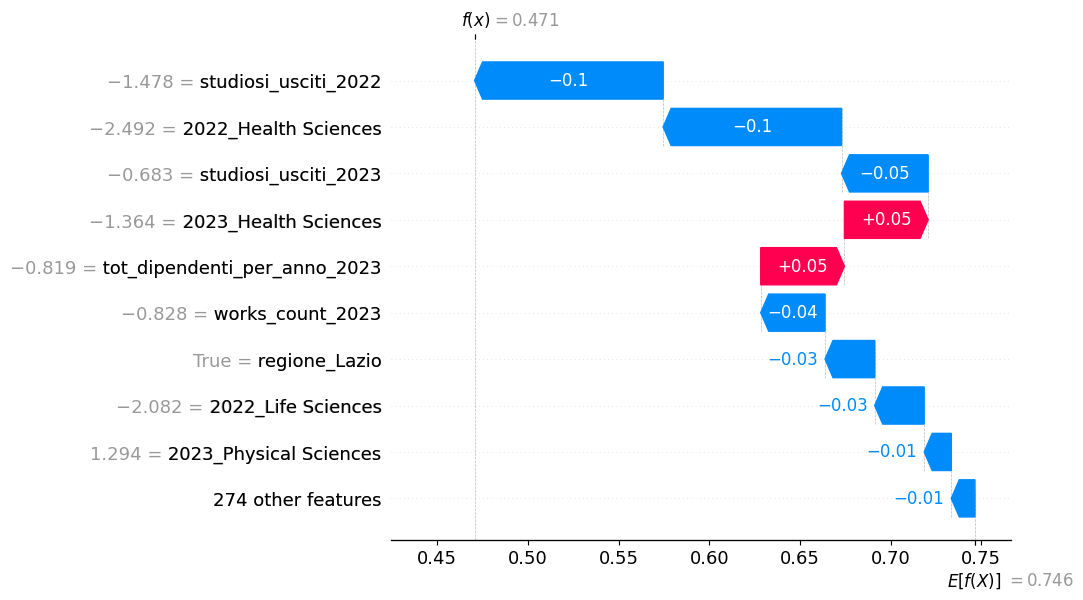

In [19]:
for i in range(n_classes):
    shap.plots.waterfall(
        shap.Explanation(
            values=shap_values_city[0, :, i],
            base_values=explainer_city.expected_value[i],
            data=x_train_sample.iloc[0, :].values,
            feature_names=feature_names
        )
    )

4.1 Ri Allenamento del modello

In [20]:
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score, classification_report
from sklearn.svm import SVC

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [22]:
# Se ha 3 dimensioni (multiclass), fai mean su samples e classes
shap_importance_city = np.mean(np.abs(shap_values_city), axis=(0, 2))

In [23]:
# creazione dataframe
feature_importance = pd.DataFrame({
    "feature": X.columns,
    "mean_abs_shap": shap_importance_city
})

# ordinamento
feature_importance = feature_importance.sort_values(
    by="mean_abs_shap",
    ascending=False
)

In [24]:
feature_importance

,feature,mean_abs_shap
5,studiosi_usciti_2022,0.059801
4,tot_dipendenti_per_anno_2022,0.044026
8,studiosi_usciti_2023,0.043920
7,tot_dipendenti_per_anno_2023,0.034010
0,works_count_2023,0.019969
...,...,...
131,city_Faenza,0.000000
132,city_Ferrara,0.000000
133,city_Fisciano,0.000000
136,city_Foligno,0.000000


In [25]:
svm_params = {
    'kernel' : ['rbf', 'linear', 'poly', 'sigmoid'], 
    'degree' : [2,3,5],
    'C' : [0.001, 0.01, 0.1, 1],
    'gamma': ['scale', 'auto'], 
    'class_weight' : ['balanced'],
    'max_iter' : [100, 300, 500, 1000]
}
svm_grid = GridSearchCV(SVC(probability=True), 
                        svm_params,
                        cv = cv,
                        scoring = 'f1_macro',
                        verbose = 1)

validation_dict = {}

In [26]:
def different_idx(shap_values, results_dict, X_train_df, X_val_df, y_train, y_val):
    
    shap_importance = np.mean(np.abs(shap_values), axis=(0, 2))
    
    best_f1 = -1
    best_model = None
    best_X_train = None
    best_X_val = None
    best_features = None
    
    for i in range(40, 60):
        top_idx      = np.argsort(shap_importance)[::-1][:i]
        top_features = np.array(X_val_df.columns)[top_idx]
        
        X_train_top = X_train_df[top_features]
        X_val_top   = X_val_df[top_features]
        
        svm_grid.fit(X_train_top, y_train)
        svm = svm_grid.best_estimator_
        
        y_pred = svm.predict(X_val_top)
        acc = accuracy_score(y_val, y_pred)
        f1  = f1_score(y_val, y_pred, average="macro")
        
        results_dict[i] = {
            'n_features' : i,
            'accuracy'   : round(acc, 4),
            'f1'         : round(f1, 4),
            'best_params': svm_grid.best_params_
        }
        
        # ✅ Aggiorna il best solo se questo i è migliore
        if f1 > best_f1:
            best_f1       = f1
            best_model    = svm
            best_X_train  = X_train_top
            best_X_val    = X_val_top
            best_features = top_features
    
    return results_dict, best_model, best_X_train, best_X_val, best_features

results = {}
# Chiamata
results, svm_model, new_x_train, new_x_val, top_features = different_idx(
    shap_values_city, results,
    X_train_df=x_train, X_val_df=x_val,
    y_train=y_train, y_val=y_val
)

# Ora new_x_val ha esattamente le features su cui svm_model è stato fittato
y_pred_city = svm_model.predict(new_x_val)

Fitting 5 folds for each of 384 candidates, totalling 1920 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
 

Fitting 5 folds for each of 384 candidates, totalling 1920 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
 

Fitting 5 folds for each of 384 candidates, totalling 1920 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
 

... (30 outputs left out)

Fitting 5 folds for each of 384 candidates, totalling 1920 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
 

Fitting 5 folds for each of 384 candidates, totalling 1920 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
 

In [27]:
df_results = pd.DataFrame(results).T.reset_index(drop=True)
df_results = df_results.sort_values(by='f1', ascending=False)

In [28]:
df_results

,n_features,accuracy,f1,best_params
15,55,0.6304,0.5901,"{'C': 1, 'class_weight': 'balanced', 'degree':..."
14,54,0.6304,0.5881,"{'C': 1, 'class_weight': 'balanced', 'degree':..."
16,56,0.6087,0.5722,"{'C': 1, 'class_weight': 'balanced', 'degree':..."
8,48,0.6217,0.57,"{'C': 1, 'class_weight': 'balanced', 'degree':..."
13,53,0.6087,0.565,"{'C': 1, 'class_weight': 'balanced', 'degree':..."
7,47,0.6174,0.5634,"{'C': 1, 'class_weight': 'balanced', 'degree':..."
17,57,0.6217,0.5629,"{'C': 1, 'class_weight': 'balanced', 'degree':..."
3,43,0.613,0.5529,"{'C': 1, 'class_weight': 'balanced', 'degree':..."
10,50,0.6043,0.5515,"{'C': 1, 'class_weight': 'balanced', 'degree':..."
9,49,0.5957,0.551,"{'C': 1, 'class_weight': 'balanced', 'degree':..."


In [29]:
# 42 arriva a 76 e 67
len(top_features)

55

In [30]:
X_full = pd.concat([x_train, x_val])
y_full = pd.concat([y_train, y_val])

final_model = SVC(**svm_model.get_params())
final_model.fit(x_train[top_features], y_train)

/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",2
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [31]:
print('Classification Report per Logistic Regression')
print(classification_report(y_val, y_pred_city))
print(f'Accuracy della Logistic Regression: {accuracy_score(y_val, y_pred_city)}')
print(f'F1 Score della Logistic Regression: {f1_score(y_val, y_pred_city, average="weighted")}')

Classification Report per Logistic Regression
              precision    recall  f1-score   support

           0       0.44      0.71      0.55        21
           1       0.40      0.75      0.52        48
           2       0.90      0.58      0.71       161

    accuracy                           0.63       230
   macro avg       0.58      0.68      0.59       230
weighted avg       0.75      0.63      0.65       230

Accuracy della Logistic Regression: 0.6304347826086957
F1 Score della Logistic Regression: 0.6526405586577129


5.1 Evaluation

In [32]:
y_test_pred = svm_model.predict(x_test[top_features])
    
test_accuracy = accuracy_score(y_test, y_test_pred)
test_f1_weighted = f1_score(y_test, y_test_pred, average='weighted')
test_f1_macro = f1_score(y_test, y_test_pred, average='macro')

In [33]:
print(classification_report(y_test, y_test_pred, 
                                  target_names=lab_encoder.classes_))
print('*' * 50)

              precision    recall  f1-score   support

      inflow       0.67      0.16      0.26        38
     outflow       0.32      0.67      0.43        90
      stable       0.72      0.52      0.61       256

    accuracy                           0.52       384
   macro avg       0.57      0.45      0.43       384
weighted avg       0.62      0.52      0.53       384

**************************************************


3.2 Senza city

In [34]:
df_train_no_city = df_train.loc[:, ~df_train.columns.str.contains(r'city')]
df_test_no_city = df_test.loc[:, ~df_test.columns.str.contains(r'city')]

In [35]:
y_test_no_city = df_test_no_city['target']
x_test_no_city = df_test_no_city.drop('target', axis=1)

In [36]:
y_nocity = df_train_no_city['target']
X_nocity = df_train_no_city.drop('target', axis = 1)

In [37]:
x_train, x_val, y_train, y_val = train_test_split(X_nocity, y_nocity, test_size=0.4, random_state=42, stratify=y_nocity)

In [38]:
columns_to_scale = df_train_no_city.filter(regex=r"\d{4}").columns.tolist()
scaler = StandardScaler()

x_train[columns_to_scale] = scaler.fit_transform(x_train[columns_to_scale])
x_val[columns_to_scale] = scaler.transform(x_val[columns_to_scale])
df_test_no_city[columns_to_scale] = scaler.transform(df_test_no_city[columns_to_scale])

/var/folders/32/wr6jfczj32q0c3fcn7fkrtvr0000gn/T/ipykernel_1193/4128192901.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_no_city[columns_to_scale] = scaler.transform(df_test_no_city[columns_to_scale])


In [39]:
explainer_nocity = shap.LinearExplainer(model_no_city, x_train)
shap_values_nocity = explainer_nocity(x_val)

NameError: name 'model_no_city' is not defined


--- Classe 0 ---


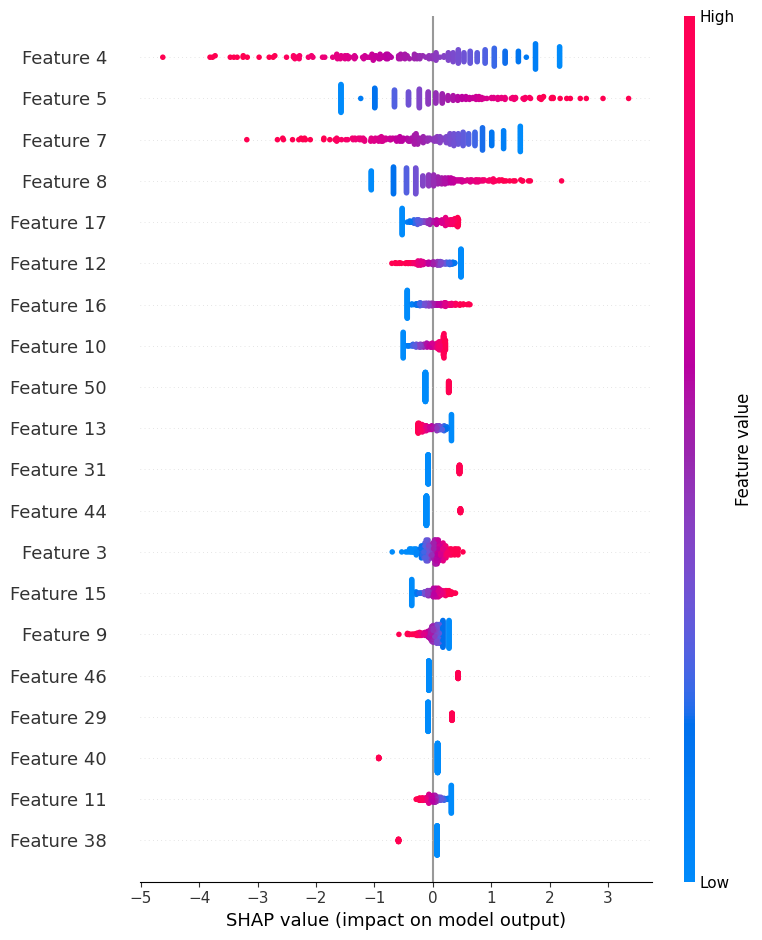


--- Classe 1 ---


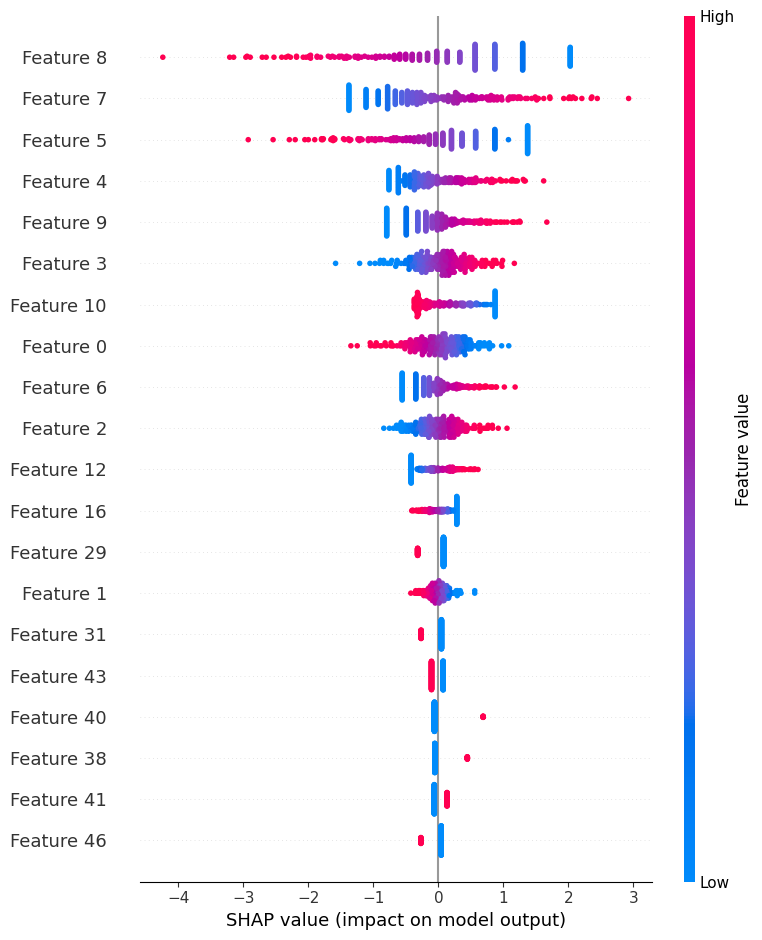


--- Classe 2 ---


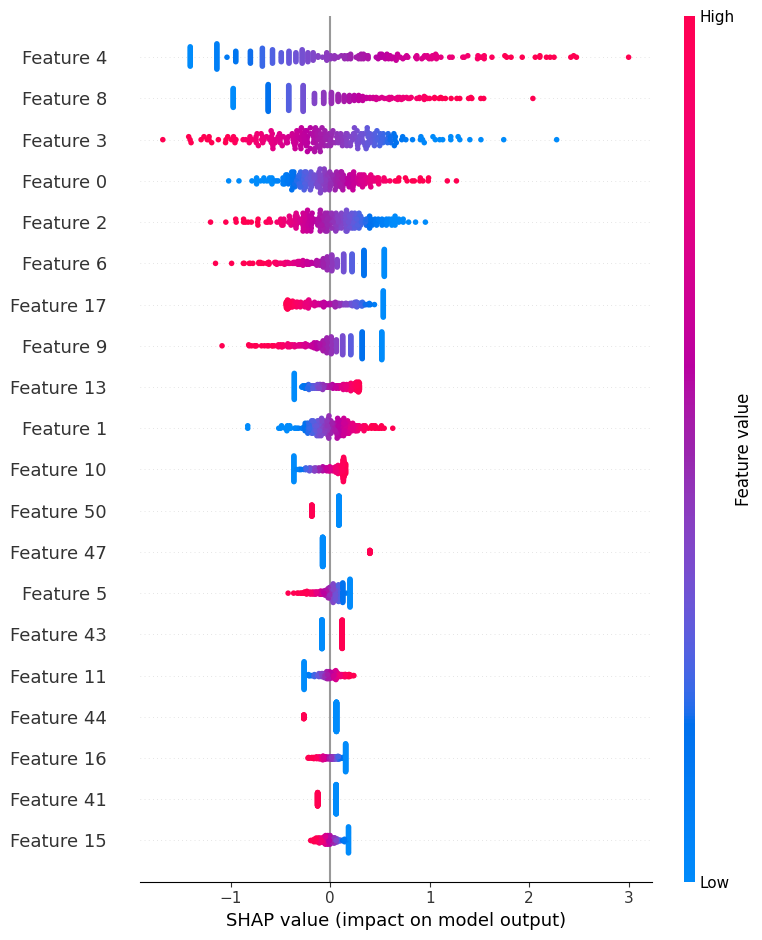

In [ ]:
shap_values_float_nocity = shap_values_nocity.values.astype(np.float64)
x_test_float_nocity = np.array(x_val, dtype=np.float64)

for i in range(n_classes):
    print(f"\n--- Classe {i} ---")
    shap.summary_plot(shap_values_float_nocity[:, :, i], x_test_float_nocity, show=True)

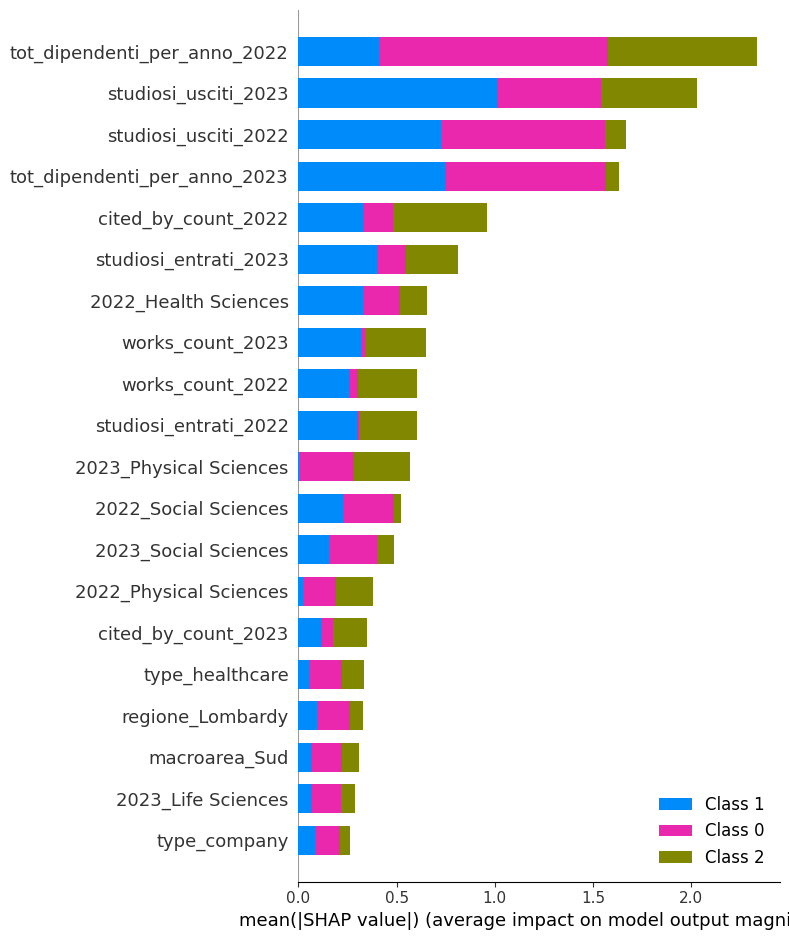

In [ ]:
shap.summary_plot(shap_values_float_nocity, x_val, plot_type="bar")

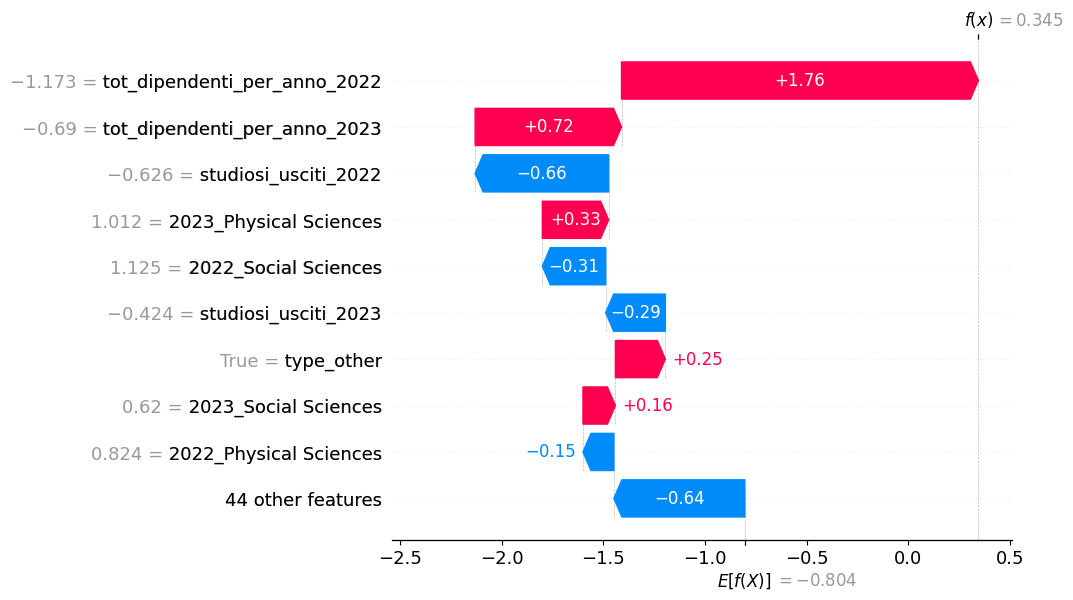

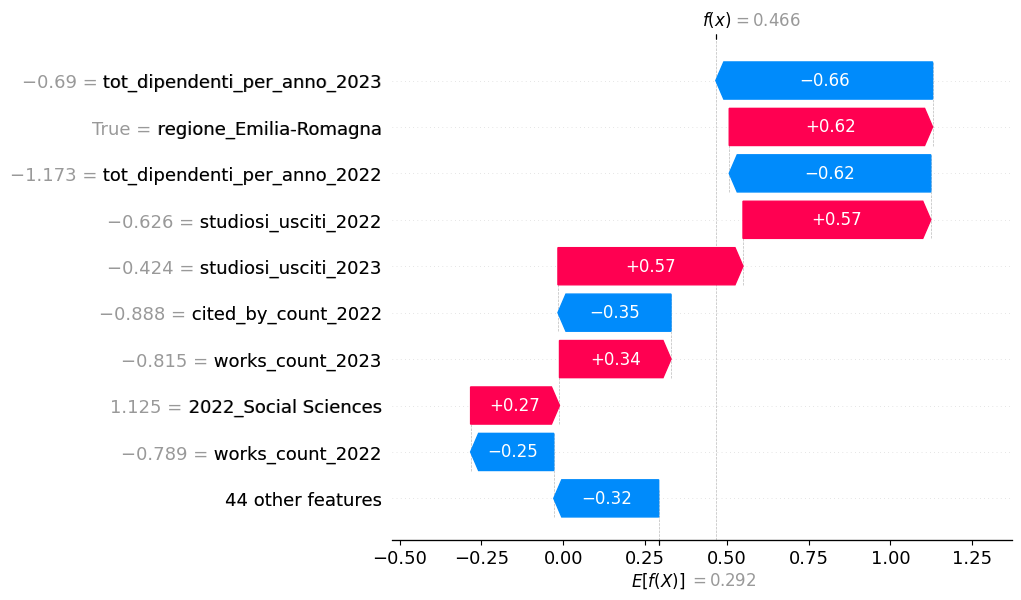

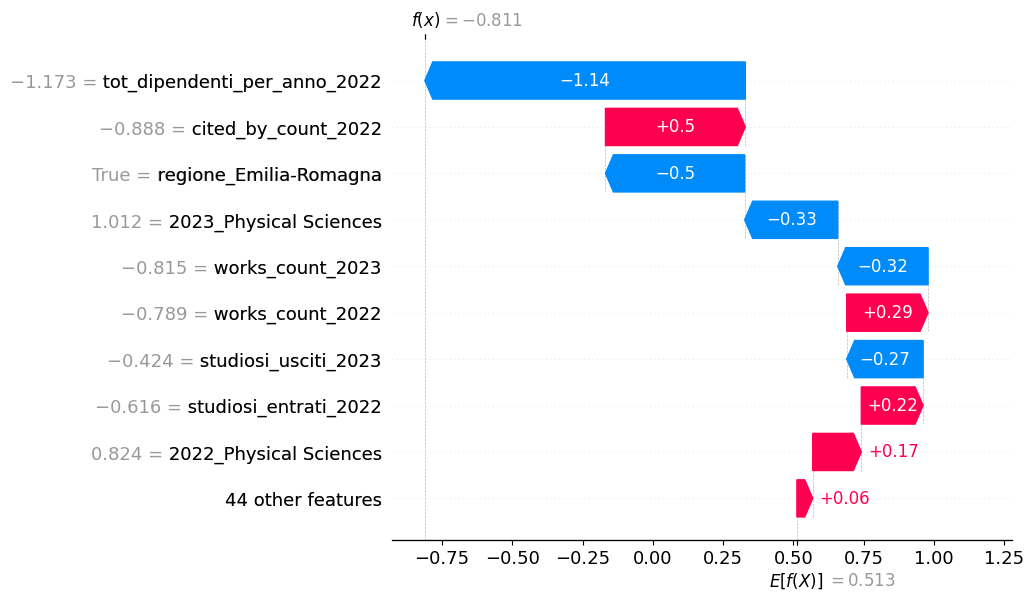

In [ ]:
for i in range(n_classes):
    shap.waterfall_plot(shap_values_nocity[0, :, i])

4.2 Ri allenamento modello no city

In [ ]:
# Estrai i valori dall'oggetto Explanation
shap_vals = shap_values_nocity.values  # shape: (n_samples, n_features) o (n_samples, n_features, n_classes)

# Se ha 3 dimensioni (multiclass), fai mean su samples e classes
if shap_vals.ndim == 3:
    shap_importance_nocity = np.abs(shap_vals).mean(axis=0).mean(axis=1)
else:
    shap_importance_nocity = np.abs(shap_vals).mean(axis=0)

top_20_idx_nocity = np.argsort(shap_importance_nocity)[::-1][:20]
top20_features_nocity = np.array(x_val.columns)[top_20_idx_nocity]
print(top20_features_nocity.tolist())

['tot_dipendenti_per_anno_2022', 'studiosi_usciti_2023', 'studiosi_usciti_2022', 'tot_dipendenti_per_anno_2023', 'cited_by_count_2022', 'studiosi_entrati_2023', '2022_Health Sciences', 'works_count_2023', 'works_count_2022', 'studiosi_entrati_2022', '2023_Physical Sciences', '2022_Social Sciences', '2023_Social Sciences', '2022_Physical Sciences', 'cited_by_count_2023', 'type_healthcare', 'regione_Lombardy', 'macroarea_Sud', '2023_Life Sciences', 'type_company']


In [ ]:
new_x_train = x_train[top20_features_nocity]
new_x_val = x_val[top20_features_nocity]

In [ ]:
grid_log_reg.fit(new_x_train, y_train)
print(grid_log_reg.best_params_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was depreca

{'C': 1, 'class_weight': 'balanced', 'max_iter': 300, 'penalty': 'l2', 'solver': 'lbfgs'}


/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was depreca

In [ ]:
lr_no_city = LogisticRegression(**grid_log_reg.best_params_, random_state=42)
lr_no_city.fit(new_x_train, y_train)

/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclas

In [ ]:
y_pred_no_city = lr_no_city.predict(new_x_val)
print('Classification Report per Logistic Regression')
print(classification_report(y_val, y_pred_no_city))
print(f'Accuracy della Logistic Regression: {accuracy_score(y_val, y_pred_no_city)}')
print(f'F1 Score della Logistic Regression: {f1_score(y_val, y_pred_no_city, average="weighted")}')

Classification Report per Logistic Regression
              precision    recall  f1-score   support

           0       0.26      0.68      0.37        25
           1       0.49      0.58      0.53        69
           2       0.73      0.44      0.55       136

    accuracy                           0.51       230
   macro avg       0.49      0.57      0.48       230
weighted avg       0.61      0.51      0.53       230

Accuracy della Logistic Regression: 0.508695652173913
F1 Score della Logistic Regression: 0.5250405915325598


5.2 Evaluation

In [ ]:
y_pred_no_city = lr_no_city.predict(x_test_no_city[top20_features_nocity])
    
test_accuracy = accuracy_score(y_test_no_city, y_pred_no_city)
test_f1_weighted = f1_score(y_test_no_city, y_pred_no_city, average='weighted')
test_f1_macro = f1_score(y_test_no_city, y_pred_no_city, average='macro')
    

print(classification_report(y_test_no_city, y_pred_no_city, 
                                  target_names=lab_encoder.classes_))
print('*' * 50)

              precision    recall  f1-score   support

      inflow       0.31      0.67      0.42        43
     outflow       0.44      0.48      0.46       115
      stable       0.70      0.52      0.60       226

    accuracy                           0.52       384
   macro avg       0.49      0.56      0.49       384
weighted avg       0.58      0.52      0.54       384

**************************************************
